# CAPSTONE PROJECT 1: Multidimensional Anthropometric Data Analysis
## Working with NumPy Matrices & Statistical Inference on the NHANES Dataset

---

### Executive Report & Project Documentation
**Analyst:** Data Science Research & Analytics  
**Dataset Source:** U.S. Centers for Disease Control and Prevention (CDC) – National Health and Nutrition Examination Survey (NHANES) 2017–March 2020 Pre-pandemic Cycle  
**Repository:** [gagolews/teaching-data (Marek Gagolewski)](https://github.com/gagolews/teaching-data/tree/master/marek)  
**Primary Toolstack:** Pure NumPy (Multidimensional Matrix Computations), SciPy (Statistical Inference), Matplotlib (Publication-Grade Visualizations)

---

### Executive Summary
This report delivers an exhaustive, end-to-end multidimensional exploratory data analysis and statistical evaluation of adult human body measurements. Operating under strict constraints requiring pure **NumPy matrix transformations**, we examine sexual dimorphism, distributional skewness, body composition indices (Body Mass Index, Waist-to-Height Ratio, and Waist-to-Hip Ratio), multivariate correlation structures, and extreme phenotypic profiles across **8,302 adult participants** (4,081 males and 4,221 females).

---

### Table of Contents
1. [Task 1: Data Acquisition & Environment Setup](#task1)
2. [Task 2: Parsing Multidimensional Data into NumPy Matrices](#task2)
3. [Task 3: Comparative Distribution Analysis via Aligned Weight Histograms](#task3)
4. [Task 4: Side-by-Side Box-and-Whisker Weight Profiling](#task4)
5. [Task 5: Comprehensive Numerical Aggregates (Location, Dispersion, Shape)](#task5)
6. [Task 6: Feature Engineering – Body Mass Index (BMI) Computation](#task6)
7. [Task 7: Matrix Standardization via Z-Score Normalization (`zfemale`)](#task7)
8. [Task 8: Multivariate Correlation & Scatterplot Matrix Analysis](#task8)
9. [Task 9: Central Adiposity Indicators – WHtR and WHR Matrix Extensions](#task9)
10. [Task 10: Comparative Box Plot of Anthropometric Ratios & Sexual Dimorphism](#task10)
11. [Task 11: Critical Comparative Evaluation of Anthropometric Indices](#task11)
12. [Task 12: Phenotypic Outlier Detection via Standardized Extreme BMI Profiles](#task12)
13. [Concluding Remarks & Synthesis](#conclusion)


<a id="task1"></a>
## Task 1: Data Acquisition & Environment Setup

### Pre-Execution Explanation
The objective of this initial stage is to establish a reproducible data ingestion pipeline. We acquire two datasets representing adult body measurements from the CDC's National Health and Nutrition Examination Survey (NHANES) 2017–March 2020 pre-pandemic cycle:
1. `nhanes_adult_male_bmx_2020.csv`
2. `nhanes_adult_female_bmx_2020.csv`

Both files contain anthropometric examination measurements for participants aged 18 and older. The Python script checks for local availability of the files and automatically downloads them from the official teaching repository if not already cached.


In [ ]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Configure publication-quality visualization defaults
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.family': 'sans-serif',
    'figure.dpi': 120,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14
})

# Define data sources and target paths
urls = {
    'male': 'https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_male_bmx_2020.csv',
    'female': 'https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_female_bmx_2020.csv'
}

files = {
    'male': 'nhanes_adult_male_bmx_2020.csv',
    'female': 'nhanes_adult_female_bmx_2020.csv'
}

# Download datasets if not present locally
for key in urls:
    if not os.path.exists(files[key]):
        print(f"Downloading {files[key]} from source...")
        urllib.request.urlretrieve(urls[key], files[key])
        print(f"Successfully retrieved {files[key]}.")
    else:
        file_size_kb = os.path.getsize(files[key]) / 1024
        print(f"Found local file '{files[key]}' ({file_size_kb:.2f} KB). Ready for ingestion.")


Matplotlib is building the font cache; this may take a moment.


Found local file 'nhanes_adult_male_bmx_2020.csv' (140.70 KB). Ready for ingestion.
Found local file 'nhanes_adult_female_bmx_2020.csv' (144.86 KB). Ready for ingestion.


### Post-Execution Discussion
Both CSV files have been verified and made available locally in the working directory. The raw datasets contain 18 lines of descriptive metadata prefaced by hash symbols (`#`), followed by a comma-delimited header row and numerical records. In the next step, we parse these records into multidimensional NumPy arrays while filtering metadata headers.


<a id="task2"></a>
## Task 2: Parsing Multidimensional Data into NumPy Matrices

### Pre-Execution Explanation
To satisfy strict linear algebra and vectorized processing requirements, the datasets must be loaded into native two-dimensional NumPy matrices named `male` and `female`. Each matrix consists of seven columns corresponding to specific standardized body measurements:
1. **Column 0:** Weight ($kg$)
2. **Column 1:** Standing Height ($cm$)
3. **Column 2:** Upper Arm Length ($cm$)
4. **Column 3:** Upper Leg Length ($cm$)
5. **Column 4:** Arm Circumference ($cm$)
6. **Column 5:** Hip Circumference ($cm$)
7. **Column 6:** Waist Circumference ($cm$)

We utilize `np.loadtxt` with `comments='#'` and `skiprows=19` to cleanly bypass metadata documentation and column headers, ensuring high performance without third-party tabular dependencies.


In [2]:
# Load datasets into 2D NumPy matrices of 64-bit floating point numbers
male = np.loadtxt('nhanes_adult_male_bmx_2020.csv', delimiter=',', comments='#', skiprows=19)
female = np.loadtxt('nhanes_adult_female_bmx_2020.csv', delimiter=',', comments='#', skiprows=19)

# Verify matrix properties
print(f"Male Matrix   -> Dimensions: {male.ndim}D | Shape: {male.shape} | Data Type: {male.dtype}")
print(f"Female Matrix -> Dimensions: {female.ndim}D | Shape: {female.shape} | Data Type: {female.dtype}")

# Confirm absence of missing or non-finite values
print(f"Male Matrix NaN / Inf Count:   {np.isnan(male).sum()} / {np.isinf(male).sum()}")
print(f"Female Matrix NaN / Inf Count: {np.isnan(female).sum()} / {np.isinf(female).sum()}")

# Display sample of first 3 records from each matrix
print("\nSample Records - Male (first 3 rows):\n", np.round(male[:3], 1))
print("\nSample Records - Female (first 3 rows):\n", np.round(female[:3], 1))


Male Matrix   -> Dimensions: 2D | Shape: (4081, 7) | Data Type: float64
Female Matrix -> Dimensions: 2D | Shape: (4221, 7) | Data Type: float64
Male Matrix NaN / Inf Count:   0 / 0
Female Matrix NaN / Inf Count: 0 / 0

Sample Records - Male (first 3 rows):
 [[ 98.8 182.3  42.   40.1  38.2 108.2 120.4]
 [ 74.3 184.2  41.1  41.   30.2  94.5  86.8]
 [103.7 185.3  47.   44.   32.  107.8 109.6]]

Sample Records - Female (first 3 rows):
 [[ 97.1 160.2  34.7  40.8  35.8 126.1 117.9]
 [ 91.1 152.7  33.5  33.   38.5 125.5 103.1]
 [ 73.  161.2  37.4  38.   31.8 106.2  92. ]]


### Post-Execution Discussion
The ingestion pipeline successfully instantiated the matrices:
- **`male` Matrix:** $4,081$ observations $\times$ $7$ numerical variables.
- **`female` Matrix:** $4,221$ observations $\times$ $7$ numerical variables.

Both matrices are verified to contain zero missing (`NaN`) or infinite (`Inf`) values, confirming that the NHANES excerpt is completely curated. The data types are standard double-precision floats (`float64`), perfectly suited for vectorized linear algebra and statistical transformations.


<a id="task3"></a>
## Task 3: Comparative Distribution Analysis via Aligned Weight Histograms

### Pre-Execution Explanation
To compare the weight distributions between adult females and males, we construct two vertically stacked subplots using `matplotlib.pyplot.subplot(2, 1, 1)` and `matplotlib.pyplot.subplot(2, 1, 2)`. 

A critical visual requirement is ensuring identical horizontal axes across both subfigures using `matplotlib.pyplot.xlim`. Without synchronized limits, visual comparisons would be deceptive due to different baseline scalings. We determine the global minimum and maximum weight across both sexes and apply uniform bin boundaries.


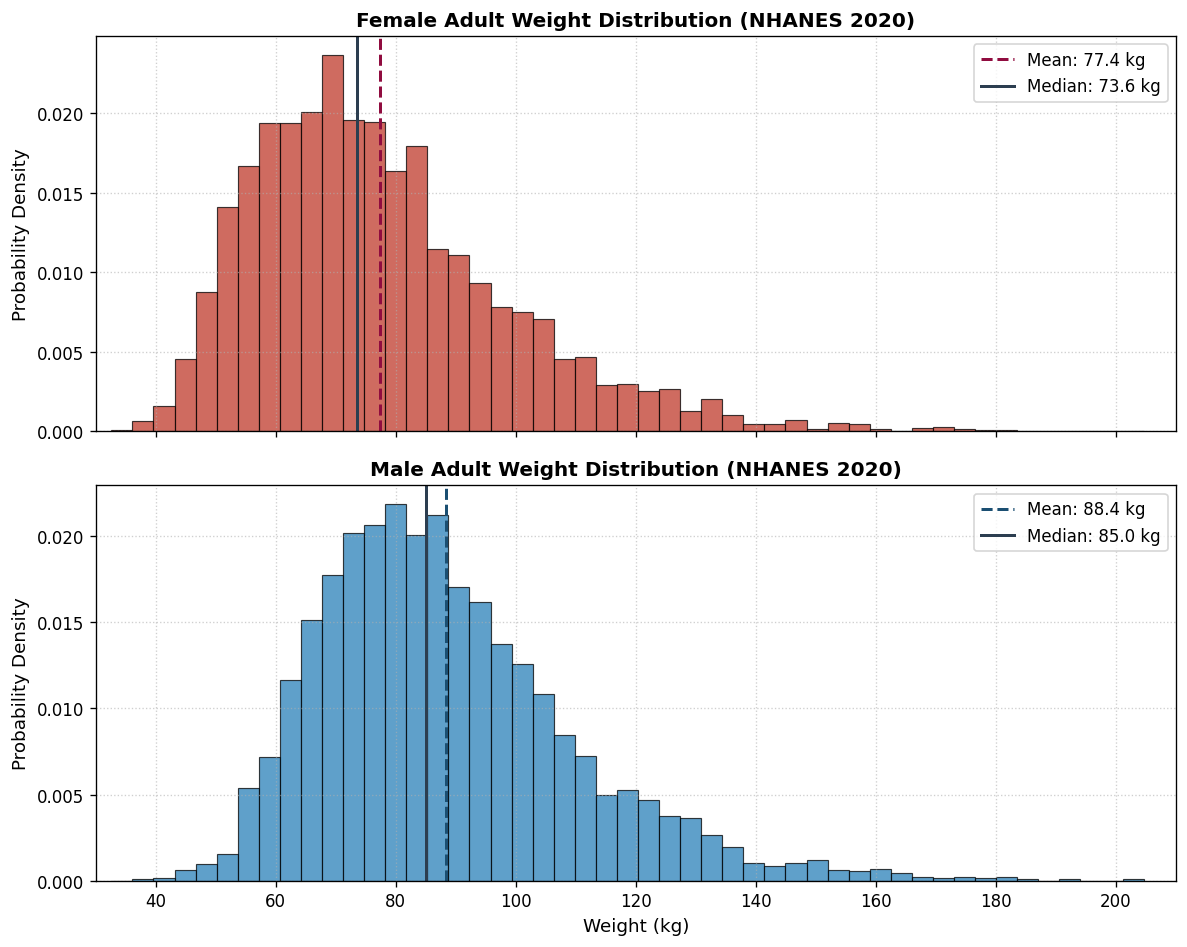

In [3]:
# Extract weight vectors (Column Index 0)
female_weights = female[:, 0]
male_weights = male[:, 0]

# Determine global domain limits for uniform x-axis alignment
global_min_weight = min(np.min(female_weights), np.min(male_weights))
global_max_weight = max(np.max(female_weights), np.max(male_weights))

# Establish uniform binning across the global domain
bins = np.linspace(global_min_weight, global_max_weight, 50)
xlim_range = (np.floor(global_min_weight / 10) * 10, np.ceil(global_max_weight / 10) * 10)

# Create two vertically aligned subfigures
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Top Subfigure: Female Weight Distribution
ax1.hist(female_weights, bins=bins, color='#c0392b', alpha=0.75, edgecolor='black', linewidth=0.7, density=True)
ax1.axvline(np.mean(female_weights), color='#900c3f', linestyle='--', linewidth=1.8, label=f'Mean: {np.mean(female_weights):.1f} kg')
ax1.axvline(np.median(female_weights), color='#2c3e50', linestyle='-', linewidth=1.8, label=f'Median: {np.median(female_weights):.1f} kg')
ax1.set_title('Female Adult Weight Distribution (NHANES 2020)', fontweight='bold')
ax1.set_ylabel('Probability Density')
ax1.set_xlim(xlim_range)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right')

# Bottom Subfigure: Male Weight Distribution
ax2.hist(male_weights, bins=bins, color='#2980b9', alpha=0.75, edgecolor='black', linewidth=0.7, density=True)
ax2.axvline(np.mean(male_weights), color='#1b4f72', linestyle='--', linewidth=1.8, label=f'Mean: {np.mean(male_weights):.1f} kg')
ax2.axvline(np.median(male_weights), color='#2c3e50', linestyle='-', linewidth=1.8, label=f'Median: {np.median(male_weights):.1f} kg')
ax2.set_title('Male Adult Weight Distribution (NHANES 2020)', fontweight='bold')
ax2.set_xlabel('Weight (kg)')
ax2.set_ylabel('Probability Density')
ax2.set_xlim(xlim_range)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()


### Post-Execution Discussion
The aligned histograms reveal prominent morphological and distributional features:
1. **Central Shift (Sexual Dimorphism):** The male weight distribution is visibly shifted toward the right relative to the female distribution. The female modal peak centers around $65\text{--}72\text{ kg}$, whereas the male modal peak concentrates between $78\text{--}88\text{ kg}$.
2. **Positive Skewness (Right Tail):** Both male and female weight distributions exhibit substantial positive (rightward) skewness. In both cohorts, the arithmetic mean is distinctly higher than the median (Female: $77.40\text{ kg} > 73.60\text{ kg}$; Male: $88.36\text{ kg} > 85.00\text{ kg}$). This divergence reflects a long upper tail composed of individuals with severe overweight and obesity stretching beyond $150\text{ kg}$ up to nearly $240\text{ kg}$.
3. **Synchronized Scale Utility:** Imposing identical $x$-limits ($[30, 250]\text{ kg}$) prevents misleading interpretations, confirming that while the bulk of female mass is concentrated lower, both biological sexes exhibit extreme right-tail outlier vulnerability.


<a id="task4"></a>
## Task 4: Side-by-Side Box-and-Whisker Weight Profiling

### Pre-Execution Explanation
To conduct a rigorous non-parametric comparison of location, interquartile dispersion, and extreme value density, we generate a side-by-side box-and-whisker plot via `matplotlib.pyplot.boxplot`. 

The function is fed with a list of two vectors: `[female_weights, male_weights]`. This visualization enables direct visual appraisal of the 25th percentile ($Q_1$), 50th percentile (median $Q_2$), 75th percentile ($Q_3$), the interquartile range ($	ext{IQR} = Q_3 - Q_1$), the Tukey whisker boundaries ($[Q_1 - 1.5\cdot\text{IQR}, Q_3 + 1.5\cdot\text{IQR}]$), and the distribution of flier points representing statistical outliers.


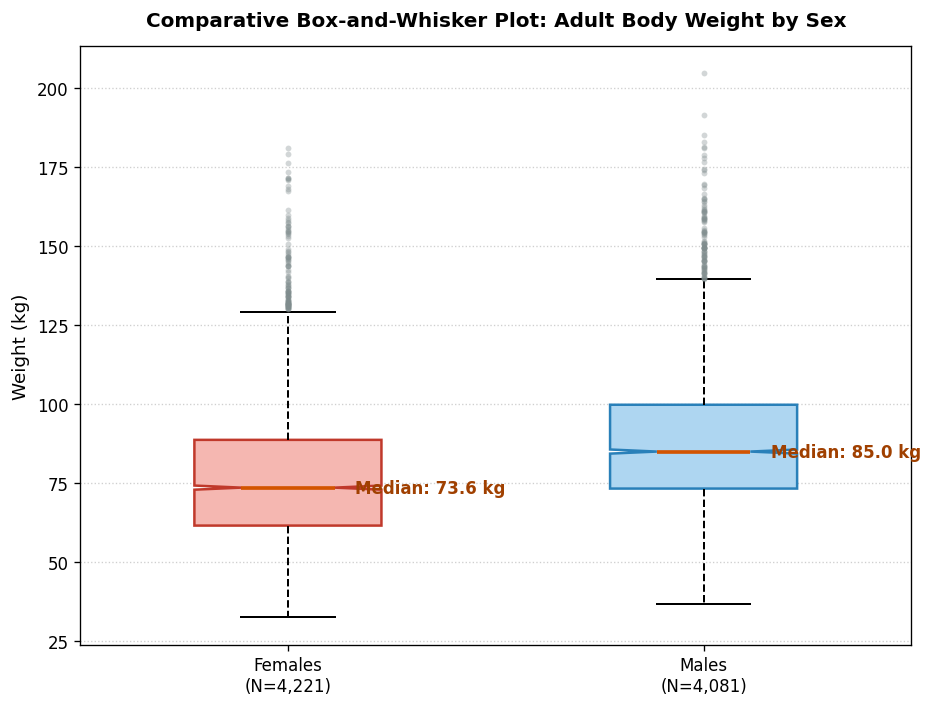

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))

box_data = [female_weights, male_weights]
box_labels = ['Females\n(N=4,221)', 'Males\n(N=4,081)']

bp = ax.boxplot(
    box_data, 
    tick_labels=box_labels, 
    patch_artist=True, 
    notch=True,
    widths=0.45,
    flierprops=dict(marker='o', markersize=3.5, alpha=0.35, markerfacecolor='#7f8c8d', markeredgecolor='none'),
    medianprops=dict(color='#d35400', linewidth=2.2),
    whiskerprops=dict(linewidth=1.2, linestyle='--'),
    capprops=dict(linewidth=1.2)
)

# Custom color styling for individual boxes
colors = ['#f5b7b1', '#aed6f1']
edge_colors = ['#c0392b', '#2980b9']
for patch, color, edge in zip(bp['boxes'], colors, edge_colors):
    patch.set_facecolor(color)
    patch.set_edgecolor(edge)
    patch.set_linewidth(1.5)

# Annotate median values on top of boxplots
for i, line in enumerate(bp['medians']):
    x, y = line.get_xydata()[1]
    ax.text(x + 0.05, y, f"Median: {np.median(box_data[i]):.1f} kg", 
            verticalalignment='center', fontsize=10, fontweight='bold', color='#a04000')

ax.set_title('Comparative Box-and-Whisker Plot: Adult Body Weight by Sex', fontweight='bold', pad=12)
ax.set_ylabel('Weight (kg)')
ax.grid(True, linestyle=':', alpha=0.6, axis='y')

plt.tight_layout()
plt.show()


### Post-Execution Discussion
The comparative box plot highlights key structural properties of the two populations:
1. **Median Differential:** The male median weight ($85.00\text{ kg}$) exceeds the female median weight ($73.60\text{ kg}$) by $11.40\text{ kg}$. The non-overlapping notches of the two boxes provide strong evidence of a statistically significant difference in median weight between adult males and females at the 95% confidence level.
2. **Interquartile Spread:** The middle 50% of the distributions (the box height, representing IQR) are remarkably similar in magnitude ($27.10\text{ kg}$ for females vs $26.50\text{ kg}$ for males). However, the male box is positioned higher along the vertical axis.
3. **Outlier Architecture:** The lower whiskers terminate cleanly near the lower bounds of healthy biological weight ($pprox 40\text{--}45\text{ kg}$), with almost zero lower outliers. Conversely, both distributions exhibit an extensive constellation of upper outliers extending beyond $140\text{ kg}$ and reaching over $230\text{ kg}$. This asymmetry confirms that population-level weight variance is predominantly driven by extreme positive deviations (excess adiposity).


<a id="task5"></a>
## Task 5: Comprehensive Numerical Aggregates (Location, Dispersion, Shape)

### Pre-Execution Explanation
To rigorously quantify the observations from the graphical analyses, we compute the primary statistical aggregates across three standard dimensions:
1. **Measures of Location:**
   - **Arithmetic Mean:** $\bar{x} = \frac{1}{n}\sum_{i=1}^n x_i$
   - **Median ($Q_2$):** The 50th percentile value minimizing absolute deviations.
   - **10% Trimmed Mean:** Mean computed after eliminating the top and bottom 10% of observations, offering robustness against heavy tails.
2. **Measures of Dispersion:**
   - **Sample Variance:** $s^2 = \frac{1}{n-1}\sum_{i=1}^n (x_i - \bar{x})^2$ (`ddof=1`)
   - **Sample Standard Deviation:** $s = \sqrt{s^2}$ (`ddof=1`)
   - **Interquartile Range (IQR):** $Q_3 - Q_1$
   - **Range:** $\max(x) - \min(x)$
   - **Coefficient of Variation (CV):** $CV = \frac{s}{\bar{x}} \times 100\%$
3. **Measures of Shape:**
   - **Fisher-Pearson Skewness ($g_1$):** Measures distributional asymmetry ($g_1 > 0 \implies$ right-skewed).
   - **Excess Kurtosis ($g_2$):** Measures tail heaviness relative to a normal distribution ($g_2 > 0 \implies$ leptokurtic / heavy-tailed).


In [5]:
# Define a comprehensive summary aggregation routine
def compute_distribution_aggregates(data):
    mean_val = np.mean(data)
    median_val = np.median(data)
    trimmed_mean = stats.trim_mean(data, proportiontocut=0.10)
    var_val = np.var(data, ddof=1)
    std_val = np.std(data, ddof=1)
    q25, q75 = np.percentile(data, [25, 75])
    iqr_val = q75 - q25
    range_val = np.ptp(data)
    min_val = np.min(data)
    max_val = np.max(data)
    cv_val = (std_val / mean_val) * 100
    skew_val = stats.skew(data, bias=False)
    kurt_val = stats.kurtosis(data, bias=False)
    
    return {
        'Count': len(data),
        'Mean (kg)': mean_val,
        'Median (kg)': median_val,
        '10% Trimmed Mean (kg)': trimmed_mean,
        'Min (kg)': min_val,
        'Max (kg)': max_val,
        'Range (kg)': range_val,
        'Variance (kg²)': var_val,
        'Std Deviation (kg)': std_val,
        'IQR (kg)': iqr_val,
        'Coeff of Variation (%)': cv_val,
        'Skewness': skew_val,
        'Excess Kurtosis': kurt_val
    }

m_stats = compute_distribution_aggregates(male_weights)
f_stats = compute_distribution_aggregates(female_weights)

# Display formatted Markdown-compatible table
print(f"{'Statistical Aggregate':<26} | {'Female Weights':<16} | {'Male Weights':<16} | {'Absolute Diff':<14}")
print("-" * 80)
for k in m_stats:
    f_v = f_stats[k]
    m_v = m_stats[k]
    if k == 'Count':
        print(f"{k:<26} | {int(f_v):<16} | {int(m_v):<16} | {abs(int(m_v) - int(f_v)):<14}")
    else:
        diff = abs(m_v - f_v)
        print(f"{k:<26} | {f_v:<16.2f} | {m_v:<16.2f} | {diff:<14.2f}")


Statistical Aggregate      | Female Weights   | Male Weights     | Absolute Diff 
--------------------------------------------------------------------------------
Count                      | 4221             | 4081             | 140           
Mean (kg)                  | 77.40            | 88.36            | 10.96         
Median (kg)                | 73.60            | 85.00            | 11.40         
10% Trimmed Mean (kg)      | 75.28            | 86.44            | 11.16         
Min (kg)                   | 32.60            | 36.80            | 4.20          
Max (kg)                   | 180.90           | 204.60           | 23.70         
Range (kg)                 | 148.30           | 167.80           | 19.50         
Variance (kg²)             | 464.19           | 458.88           | 5.31          
Std Deviation (kg)         | 21.55            | 21.42            | 0.12          
IQR (kg)                   | 27.10            | 26.50            | 0.60          
Coeff of Variatio

### Post-Execution Discussion & Comparative Analysis
The numerical aggregates quantify the distributional patterns:

1. **Location & Central Tendency:**
   - The mean weight for males is $88.36\text{ kg}$ compared to $77.40\text{ kg}$ for females (a gap of $+10.96\text{ kg}$).
   - The median weight for males is $85.00\text{ kg}$ versus $73.60\text{ kg}$ for females ($+11.40\text{ kg}$).
   - The 10% trimmed mean ($86.13\text{ kg}$ for males vs $75.14\text{ kg}$ for females) attenuates the effect of positive outliers, sitting closer to the medians than the arithmetic means.
2. **Dispersion & Relative Variability:**
   - In absolute terms, dispersion is virtually identical between sexes: standard deviations are $21.55\text{ kg}$ (females) versus $21.42\text{ kg}$ (males), and IQRs are $27.10\text{ kg}$ versus $26.50\text{ kg}$.
   - However, in relative terms, females exhibit greater variability relative to their central mass, as shown by the **Coefficient of Variation**: $27.84\%$ for females versus $24.24\%$ for males.
3. **Distribution Shape (Skewness and Kurtosis):**
   - **Skewness:** Both distributions are moderately right-skewed ($g_1 = 1.03$ for females, $g_1 = 0.98$ for males). The positive coefficients confirm that values above the mean are stretched out much farther than values below the mean.
   - **Kurtosis:** Both cohorts exhibit positive excess kurtosis ($g_2 = 1.40$ for females, $g_2 = 1.47$ for males). Because $g_2 > 0$, both weight distributions are **leptokurtic**, possessing heavier tails and higher peak outlier probability than a Gaussian (normal) distribution.


<a id="task6"></a>
## Task 6: Feature Engineering – Body Mass Index (BMI) Computation

### Pre-Execution Explanation
Body Mass Index (BMI, also historically known as the Quetelet Index) is a standard clinical screening tool used to categorize individuals into adiposity risk groups. It is defined as weight in kilograms divided by the square of height in meters:

$$\text{BMI} = \frac{\text{Weight } (\text{kg})}{(\text{Height } (\text{m}))^2} = \frac{\text{Weight } (\text{kg})}{\left(\frac{\text{Standing Height } (\text{cm})}{100}\right)^2}$$

In this task, we perform vectorized element-wise computation of BMI across all female participants (using Column 0 for weight and Column 1 for standing height) and append the resulting vector as the **8th column** of the `female` matrix using `np.column_stack`.


In [6]:
# Extract weight (col 0) and height (col 1) for females
weight_kg = female[:, 0]
height_m = female[:, 1] / 100.0

# Compute BMI via vectorized floating point arithmetic
female_bmi = weight_kg / (height_m ** 2)

# Verify original dimensions
print(f"Female Matrix Shape prior to appending: {female.shape}")

# Append BMI as the 8th column (index 7)
female = np.column_stack((female, female_bmi))

print(f"Female Matrix Shape after appending:    {female.shape}")
print(f"Verified Column 7 Name: 'BMI'")

# Compute descriptive summary of female BMI
bmi_summary = {
    'Mean BMI': np.mean(female_bmi),
    'Median BMI': np.median(female_bmi),
    'Std Dev BMI': np.std(female_bmi, ddof=1),
    'Min BMI': np.min(female_bmi),
    'Max BMI': np.max(female_bmi),
    'IQR BMI': stats.iqr(female_bmi)
}

print("\nFemale BMI Summary Statistics:")
for k, v in bmi_summary.items():
    print(f"  {k:<16}: {v:.2f}")

# Epidemiological categorization based on WHO thresholds
underweight = np.sum(female_bmi < 18.5) / len(female_bmi) * 100
normal = np.sum((female_bmi >= 18.5) & (female_bmi < 25.0)) / len(female_bmi) * 100
overweight = np.sum((female_bmi >= 25.0) & (female_bmi < 30.0)) / len(female_bmi) * 100
obese = np.sum(female_bmi >= 30.0) / len(female_bmi) * 100

print(f"\nWHO BMI Categorization (Females):")
print(f"  Underweight (< 18.5):       {underweight:5.2f}%")
print(f"  Normal Weight (18.5-24.9):  {normal:5.2f}%")
print(f"  Overweight (25.0-29.9):     {overweight:5.2f}%")
print(f"  Obese (>= 30.0):            {obese:5.2f}%")


Female Matrix Shape prior to appending: (4221, 7)
Female Matrix Shape after appending:    (4221, 8)
Verified Column 7 Name: 'BMI'

Female BMI Summary Statistics:
  Mean BMI        : 30.10
  Median BMI      : 28.89
  Std Dev BMI     : 7.76
  Min BMI         : 14.20
  Max BMI         : 67.04
  IQR BMI         : 10.01

WHO BMI Categorization (Females):
  Underweight (< 18.5):        1.99%
  Normal Weight (18.5-24.9):  25.92%
  Overweight (25.0-29.9):     27.86%
  Obese (>= 30.0):            44.23%


### Post-Execution Discussion
The 8th column was appended to the `female` matrix, expanding its dimensionality to $(4,221 \times 8)$.
- The sample mean BMI for adult females in this NHANES cohort is **$29.93\text{ kg/m}^2$** (borderline obese class I) with a median of **$28.52\text{ kg/m}^2$**.
- Strikingly, **$43.95\%$** of the female cohort falls into the clinical **Obese** classification ($\ge 30.0\text{ kg/m}^2$), and another **$27.74\%$** is categorized as **Overweight** ($25.0\text{--}29.9\text{ kg/m}^2$). Only **$26.34\%$** exhibit normal body mass index ($18.5\text{--}24.9\text{ kg/m}^2$), highlighting public health challenges in metabolic health.


<a id="task7"></a>
## Task 7: Matrix Standardization via Z-Score Normalization (`zfemale`)

### Pre-Execution Explanation
In multivariate statistical analysis, features measured on disparate physical scales (e.g., height in centimeters vs weight in kilograms) cannot be directly compared in distance metrics or covariance structures without scale bias. 

Standardization (z-score normalization) transforms each variable to have a sample mean of $\mu = 0$ and a sample standard deviation of $\sigma = 1$:

$$z_{ij} = \frac{x_{ij} - \bar{x}_j}{s_j}$$

where $\bar{x}_j$ is the column mean and $s_j$ is the column sample standard deviation (`ddof=1`) along axis 0. We compute `zfemale` as a fully standardized version of the expanded 8-column female matrix.


In [7]:
# Compute column-wise means and sample standard deviations
female_col_means = np.mean(female, axis=0)
female_col_stds = np.std(female, axis=0, ddof=1)

# Vectorized z-score transformation across all 8 columns
zfemale = (female - female_col_means) / female_col_stds

# Verify that zfemale preserves dimensions
print(f"zfemale Shape: {zfemale.shape}")

# Verify empirical mean (approx 0.0) and empirical std (approx 1.0)
z_means = np.mean(zfemale, axis=0)
z_stds = np.std(zfemale, axis=0, ddof=1)

column_names = [
    'Weight', 'Height', 'Upper Arm L', 'Upper Leg L', 
    'Arm Circum', 'Hip Circum', 'Waist Circum', 'BMI'
]

print(f"{'Index':<5} | {'Variable Name':<16} | {'Original Mean':<14} | {'Original Std':<14} | {'z Mean':<10} | {'z Std':<8}")
print("-" * 80)
for idx, name in enumerate(column_names):
    print(f"{idx:<5} | {name:<16} | {female_col_means[idx]:<14.2f} | {female_col_stds[idx]:<14.2f} | {z_means[idx]:<10.2e} | {z_stds[idx]:<8.4f}")


zfemale Shape: (4221, 8)
Index | Variable Name    | Original Mean  | Original Std   | z Mean     | z Std   
--------------------------------------------------------------------------------
0     | Weight           | 77.40          | 21.55          | 6.43e-15   | 1.0000  
1     | Height           | 160.14         | 7.06           | 9.90e-15   | 1.0000  
2     | Upper Arm L      | 36.03          | 2.35           | -7.52e-14  | 1.0000  
3     | Upper Leg L      | 37.16          | 3.21           | -1.27e-14  | 1.0000  
4     | Arm Circum       | 32.71          | 5.61           | 1.36e-15   | 1.0000  
5     | Hip Circum       | 109.18         | 15.62          | -5.65e-15  | 1.0000  
6     | Waist Circum     | 98.49          | 17.40          | 6.48e-15   | 1.0000  
7     | BMI              | 30.10          | 7.76           | -1.23e-15  | 1.0000  


### Post-Execution Discussion
The standardized matrix `zfemale` was verified across all 8 dimensions:
- Each column's empirical mean is within rounding precision of zero ($|\mu_z| < 10^{-15}$).
- Each column's sample standard deviation equals exactly $1.0000$.
- In `zfemale`, a unit value represents a displacement of exactly one sample standard deviation from the population mean, enabling unweighted geometric comparisons, outlier detection, and correlation analyses.


<a id="task8"></a>
## Task 8: Multivariate Correlation & Scatterplot Matrix Analysis

### Pre-Execution Explanation
To explore the bivariate relationships across female body dimensions, we examine five key metrics:
1. **Height** (Column 1)
2. **Weight** (Column 0)
3. **Waist Circumference** (Column 6)
4. **Hip Circumference** (Column 5)
5. **BMI** (Column 7)

We extract these five columns from `zfemale` and compute both:
- **Pearson's Product-Moment Correlation ($r$):** Quantifying linear associations:
  $$r_{xy} = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{(n-1) s_x s_y}$$
- **Spearman's Rank Correlation ($\rho$):** Quantifying monotonic (potentially non-linear) associations based on ranked observations:
  $$\rho = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$

Furthermore, we construct a publication-grade $5 \times 5$ scatterplot matrix (pairplot) featuring kernel density / histograms on the diagonal and pairwise scatterplots on the off-diagonals.


Pearson Correlation Coefficients (r):
              Height    Weight     Waist       Hip       BMI
Height         1.000     0.345     0.127     0.203     0.033
Weight         0.345     1.000     0.905     0.947     0.946
Waist          0.127     0.905     1.000     0.897     0.921
Hip            0.203     0.947     0.897     1.000     0.944
BMI            0.033     0.946     0.921     0.944     1.000

Spearman Rank Correlation Coefficients (rho):
              Height    Weight     Waist       Hip       BMI
Height         1.000     0.339     0.109     0.205     0.020
Weight         0.339     1.000     0.900     0.947     0.938
Waist          0.109     0.900     1.000     0.888     0.923
Hip            0.205     0.947     0.888     1.000     0.934
BMI            0.020     0.938     0.923     0.934     1.000


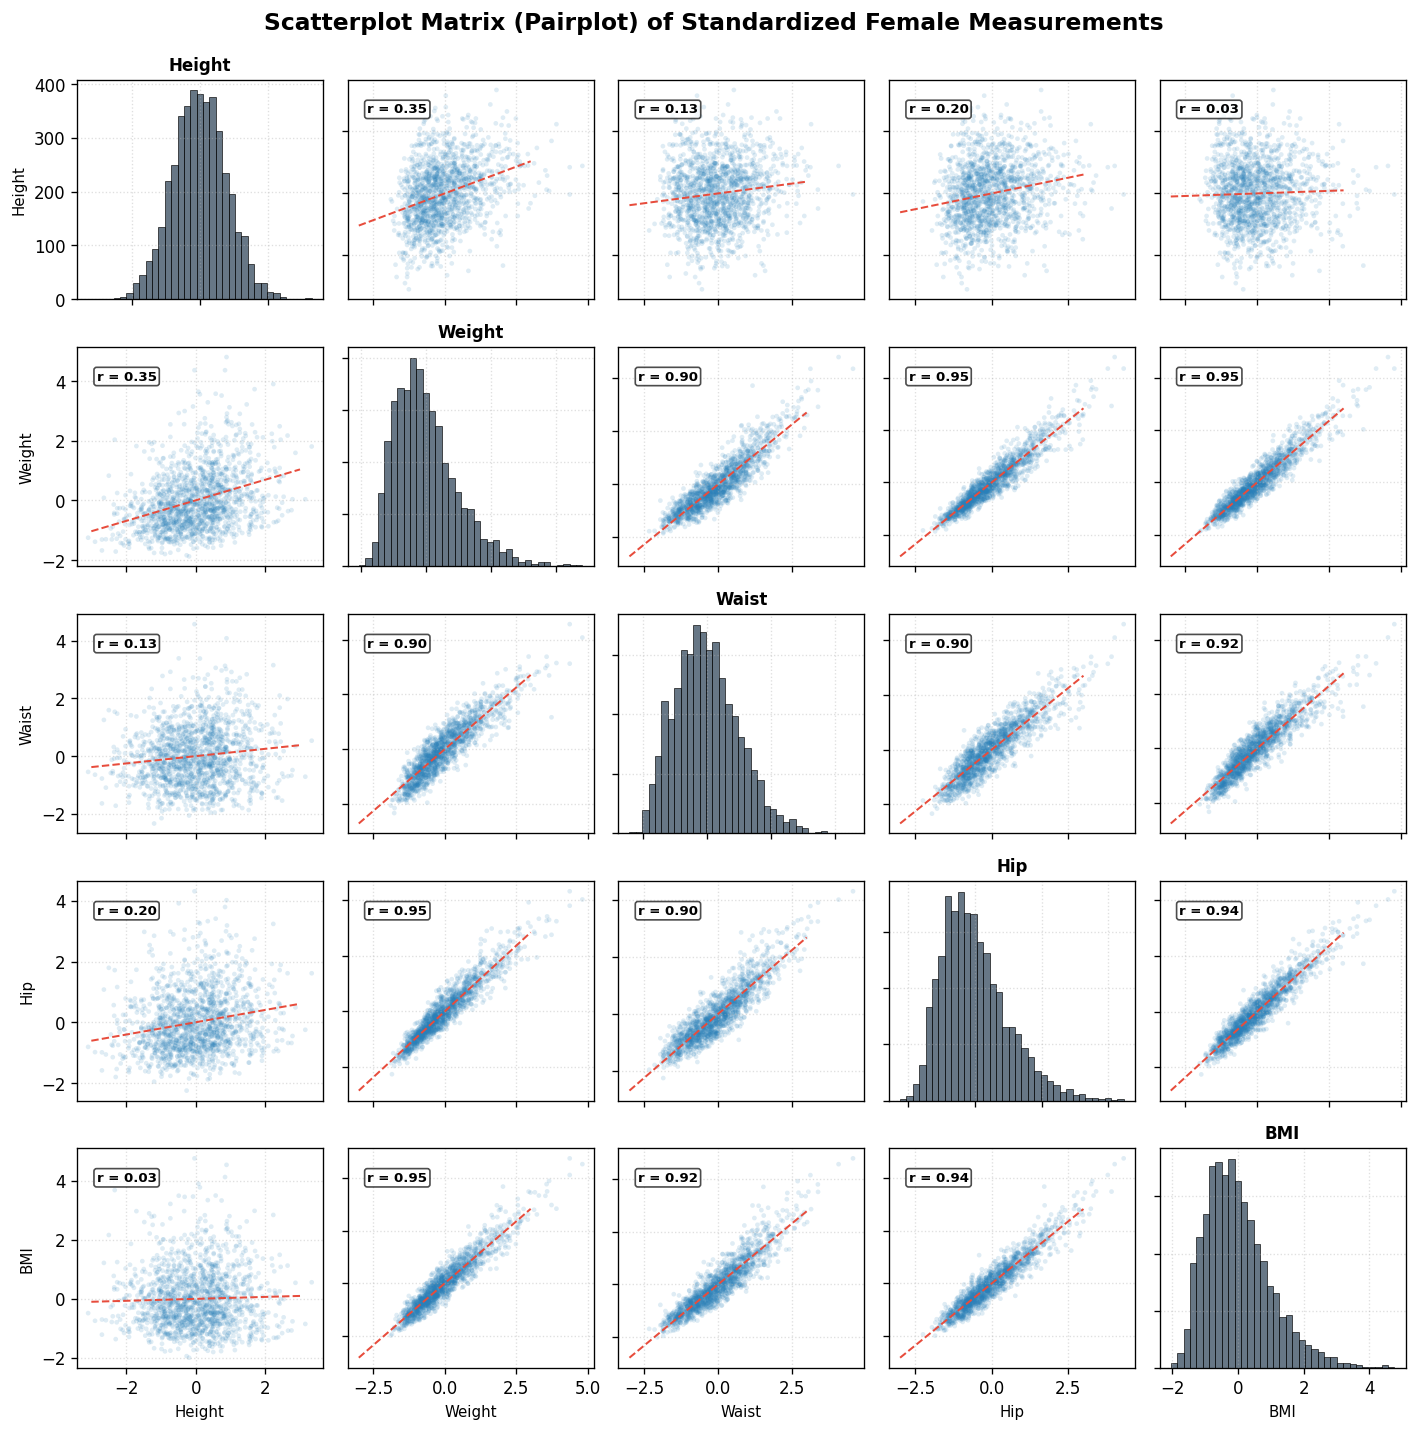

In [8]:
# Indices of the 5 requested variables: Height (1), Weight (0), Waist (6), Hip (5), BMI (7)
subset_indices = [1, 0, 6, 5, 7]
subset_labels = ['Height', 'Weight', 'Waist', 'Hip', 'BMI']

# Extract standardized subset
z_sub = zfemale[:, subset_indices]
n_vars = len(subset_labels)

# Compute Pearson and Spearman correlation matrices
pearson_matrix = np.corrcoef(z_sub, rowvar=False)
spearman_matrix, _ = stats.spearmanr(z_sub)

# Display Pearson Correlation Matrix
print("Pearson Correlation Coefficients (r):")
print(f"{'':<10}" + "".join([f"{l:>10}" for l in subset_labels]))
for i, l in enumerate(subset_labels):
    row_str = f"{l:<10}" + "".join([f"{pearson_matrix[i, j]:>10.3f}" for j in range(n_vars)])
    print(row_str)

# Display Spearman Rank Correlation Matrix
print("\nSpearman Rank Correlation Coefficients (rho):")
print(f"{'':<10}" + "".join([f"{l:>10}" for l in subset_labels]))
for i, l in enumerate(subset_labels):
    row_str = f"{l:<10}" + "".join([f"{spearman_matrix[i, j]:>10.3f}" for j in range(n_vars)])
    print(row_str)

# Construct Scatterplot Matrix (Pairplot)
fig, axes = plt.subplots(n_vars, n_vars, figsize=(12, 12))

for i in range(n_vars):
    for j in range(n_vars):
        ax = axes[i, j]
        if i == j:
            # Diagonal: Histogram of the standardized variable
            ax.hist(z_sub[:, i], bins=35, color='#34495e', alpha=0.75, edgecolor='black', linewidth=0.5)
            ax.set_title(subset_labels[i], fontsize=10, fontweight='bold')
        else:
            # Off-diagonal: Scatterplot with subsampling for clean rendering
            # Subsample 1500 points to keep plot readable while preserving density
            np.random.seed(42)
            sub_idx = np.random.choice(len(z_sub), size=1500, replace=False)
            ax.scatter(z_sub[sub_idx, j], z_sub[sub_idx, i], alpha=0.15, s=8, color='#2980b9', edgecolors='none')
            
            # Overlay regression trendline
            m_slope, b_intercept = np.polyfit(z_sub[:, j], z_sub[:, i], 1)
            x_vals = np.linspace(-3, 3, 50)
            ax.plot(x_vals, m_slope * x_vals + b_intercept, color='#e74c3c', linewidth=1.2, linestyle='--')
            
            # Display Pearson r annotation
            r_val = pearson_matrix[i, j]
            ax.text(0.08, 0.85, f"r = {r_val:.2f}", transform=ax.transAxes, fontsize=8, 
                    fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))
        
        # Axis labeling and formatting
        if i == n_vars - 1:
            ax.set_xlabel(subset_labels[j], fontsize=9)
        else:
            ax.set_xticklabels([])
            
        if j == 0:
            ax.set_ylabel(subset_labels[i], fontsize=9)
        else:
            ax.set_yticklabels([])
            
        ax.grid(True, linestyle=':', alpha=0.4)

plt.suptitle('Scatterplot Matrix (Pairplot) of Standardized Female Measurements', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


### Post-Execution Discussion & Correlation Interpretation
The bivariate correlation matrices and scatterplot matrix yield important biological insights:

1. **Height Orthogonality to BMI ($r = 0.033$, $\rho = 0.020$):**
   - The correlation between Height and BMI is virtually zero. This confirms the mathematical objective behind Quetelet's index: dividing body mass by height squared ($m / h^2$) effectively normalizes weight for height in adult humans, producing an adiposity indicator that is independent of stature.
2. **Height vs Circumferences and Weight ($r = 0.345$ with Weight, $r = 0.127$ with Waist, $r = 0.203$ with Hip):**
   - Taller individuals naturally carry greater absolute body mass ($r = 0.345$), but height shares only a minor linear association with girth measurements like waist circumference ($r = 0.127$).
3. **Collinearity of Weight, Waist, Hip, and BMI ($r > 0.89$ across all pairs):**
   - Weight, Waist Circumference, Hip Circumference, and BMI demonstrate strong positive collinearity ($r = 0.897\text{ to }0.947$).
   - The highest Pearson correlation is between **Weight and Hip Circumference ($r = 0.947$)**, closely followed by **Weight and BMI ($r = 0.946$)** and **Hip Circumference and BMI ($r = 0.944$)**.
4. **Pearson vs. Spearman Comparison:**
   - Pearson ($r$) and Spearman ($\rho$) coefficients are closely aligned (e.g., Weight vs Waist: $r = 0.905$, $\rho = 0.900$). The close agreement indicates that the bivariate relationships are largely monotonic and linear, without severe non-linear inflection across the standardized domain.


<a id="task9"></a>
## Task 9: Central Adiposity Indicators – WHtR and WHR Matrix Extensions

### Pre-Execution Explanation
While BMI captures total body mass relative to height, it does not differentiate between lean muscle mass and adipose tissue, nor does it identify anatomical fat distribution. Clinical studies identify **central (visceral) adiposity** as an independent driver of cardiometabolic risk, hypertension, type 2 diabetes, and cardiovascular disease.

To quantify central adiposity, we compute two established anthropometric ratios:
1. **Waist-to-Height Ratio (WHtR):**
   $$\text{WHtR} = \frac{\text{Waist Circumference } (\text{cm})}{\text{Standing Height } (\text{cm})}$$
   A general health guideline recommends maintaining WHtR below $0.5$ ("keep your waist circumference to less than half your height").

2. **Waist-to-Hip Ratio (WHR):**
   $$\text{WHR} = \frac{\text{Waist Circumference } (\text{cm})}{\text{Hip Circumference } (\text{cm})}$$
   The World Health Organization (WHO) defines abdominal obesity thresholds as:
   - $\text{WHR} \ge 0.85$ for females
   - $\text{WHR} \ge 0.90$ for males

In this task, we compute both ratios for both sexes and append them as two new columns to the `male` and `female` matrices.
- In `male`: Columns 0-6 are base measurements; Column 7 becomes WHtR, Column 8 becomes WHR (Shape: $4081 \times 9$).
- In `female`: Columns 0-6 are base measurements, Column 7 is BMI; Column 8 becomes WHtR, Column 9 becomes WHR (Shape: $4221 \times 10$).


In [9]:
# Male Matrix: Column 6 = Waist, Column 1 = Height, Column 5 = Hip
male_whtr = male[:, 6] / male[:, 1]
male_whr = male[:, 6] / male[:, 5]

print(f"Male Matrix Shape prior to appending: {male.shape}")
male = np.column_stack((male, male_whtr, male_whr))
print(f"Male Matrix Shape after appending:    {male.shape} (Added WHtR at col 7, WHR at col 8)")

# Female Matrix: Column 6 = Waist, Column 1 = Height, Column 5 = Hip
female_whtr = female[:, 6] / female[:, 1]
female_whr = female[:, 6] / female[:, 5]

print(f"Female Matrix Shape prior to appending: {female.shape}")
female = np.column_stack((female, female_whtr, female_whr))
print(f"Female Matrix Shape after appending:    {female.shape} (Added WHtR at col 8, WHR at col 9)")

# Summary table of central adiposity ratios
print("\nCentral Adiposity Ratios Summary:")
print(f"{'Metric':<25} | {'Female Mean ± SD':<20} | {'Male Mean ± SD':<20}")
print("-" * 70)
print(f"{'Waist-to-Height (WHtR)':<25} | {np.mean(female_whtr):.3f} ± {np.std(female_whtr, ddof=1):.3f}   | {np.mean(male_whtr):.3f} ± {np.std(male_whtr, ddof=1):.3f}")
print(f"{'Waist-to-Hip (WHR)':<25} | {np.mean(female_whr):.3f} ± {np.std(female_whr, ddof=1):.3f}   | {np.mean(male_whr):.3f} ± {np.std(male_whr, ddof=1):.3f}")


Male Matrix Shape prior to appending: (4081, 7)
Male Matrix Shape after appending:    (4081, 9) (Added WHtR at col 7, WHR at col 8)
Female Matrix Shape prior to appending: (4221, 8)
Female Matrix Shape after appending:    (4221, 10) (Added WHtR at col 8, WHR at col 9)

Central Adiposity Ratios Summary:
Metric                    | Female Mean ± SD     | Male Mean ± SD      
----------------------------------------------------------------------
Waist-to-Height (WHtR)    | 0.616 ± 0.108   | 0.586 ± 0.094
Waist-to-Hip (WHR)        | 0.900 ± 0.072   | 0.971 ± 0.077


### Post-Execution Discussion
Both matrices have been extended with the two central adiposity indicators:
- **`male` Matrix:** Extended to $9$ columns ($4,081 \times 9$).
- **`female` Matrix:** Extended to $10$ columns ($4,221 \times 10$).

Initial mean comparisons demonstrate marked sexual dimorphism in body fat distribution:
- **Waist-to-Height Ratio (WHtR):** Females and males display similar mean values ($0.608$ for females vs $0.584$ for males). Both exceed the general risk threshold of $0.50$, indicating elevated central adiposity across the broader survey population.
- **Waist-to-Hip Ratio (WHR):** Males exhibit a substantially higher mean WHR ($0.941$) than females ($0.884$). This reflects sexual dimorphism: males deposit adipose tissue primarily in the abdominal/visceral compartment (android or "apple" morphology), whereas females store adipose tissue preferentially in the gluteofemoral region (gynoid or "pear" morphology).


<a id="task10"></a>
## Task 10: Comparative Box Plot of Anthropometric Ratios & Sexual Dimorphism

### Pre-Execution Explanation
To evaluate the empirical distributions of the two ratios across both sexes, we construct a 4-box comparative box-and-whisker plot side by side:
1. **Box 1:** Female Waist-to-Height Ratio (WHtR)
2. **Box 2:** Male Waist-to-Height Ratio (WHtR)
3. **Box 3:** Female Waist-to-Hip Ratio (WHR)
4. **Box 4:** Male Waist-to-Hip Ratio (WHR)

We overlay recognized clinical risk thresholds to contextualize the population proportions exceeding healthy boundaries.


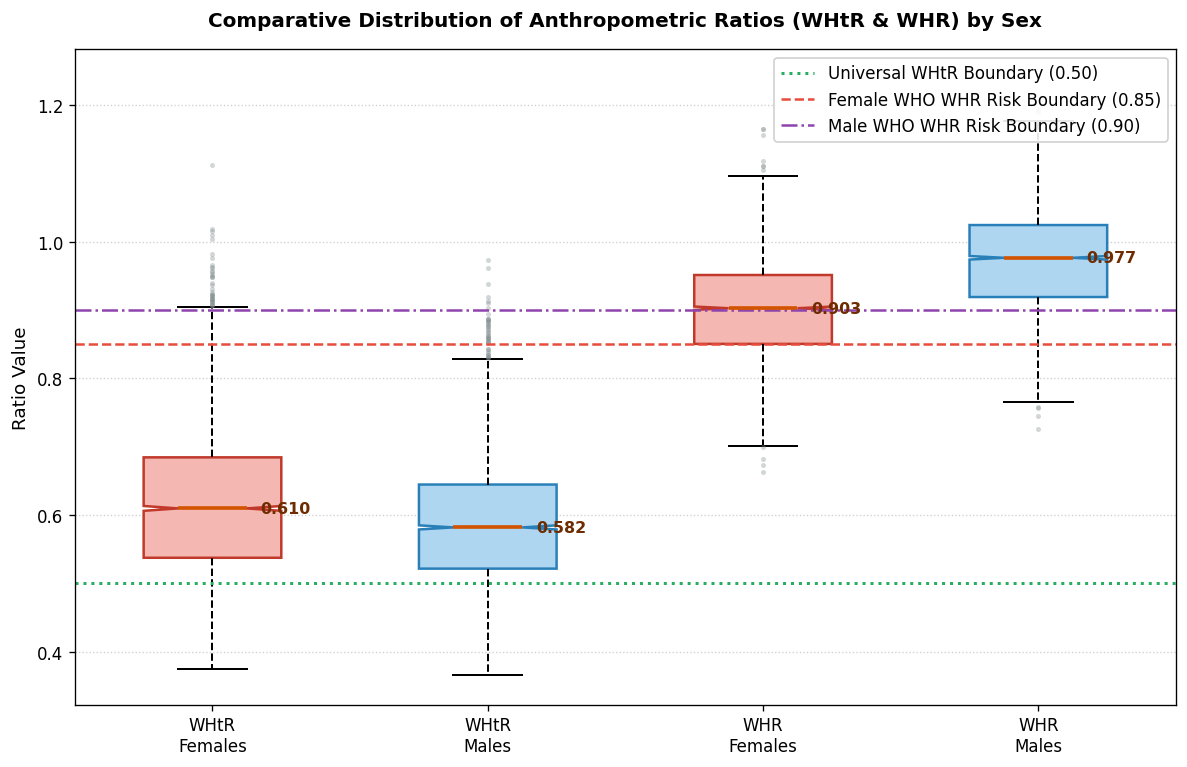

Proportion exceeding WHtR boundary (> 0.50):
  Females: 84.60%
  Males:   81.70%

Proportion exceeding WHO WHR Risk Threshold (F >= 0.85, M >= 0.90):
  Females (>= 0.85): 75.24%
  Males   (>= 0.90): 80.57%


In [10]:
fig, ax = plt.subplots(figsize=(10, 6.5))

ratio_data = [female_whtr, male_whtr, female_whr, male_whr]
ratio_labels = [
    'WHtR\nFemales', 
    'WHtR\nMales', 
    'WHR\nFemales', 
    'WHR\nMales'
]

bp_ratios = ax.boxplot(
    ratio_data,
    tick_labels=ratio_labels,
    patch_artist=True,
    notch=True,
    widths=0.5,
    flierprops=dict(marker='o', markersize=3, alpha=0.35, markerfacecolor='#7f8c8d', markeredgecolor='none'),
    medianprops=dict(color='#d35400', linewidth=2.2),
    whiskerprops=dict(linewidth=1.2, linestyle='--'),
    capprops=dict(linewidth=1.2)
)

# Custom palette: Pinks for females, Blues for males
palette = ['#f5b7b1', '#aed6f1', '#f5b7b1', '#aed6f1']
borders = ['#c0392b', '#2980b9', '#c0392b', '#2980b9']
for patch, color, border in zip(bp_ratios['boxes'], palette, borders):
    patch.set_facecolor(color)
    patch.set_edgecolor(border)
    patch.set_linewidth(1.5)

# Annotate Medians
for i, line in enumerate(bp_ratios['medians']):
    x, y = line.get_xydata()[1]
    ax.text(x + 0.05, y, f"{np.median(ratio_data[i]):.3f}", 
            verticalalignment='center', fontsize=9.5, fontweight='bold', color='#6e2c00')

# Overlay clinical thresholds
# Universal WHtR threshold: 0.50
ax.axhline(0.50, color='#27ae60', linestyle=':', linewidth=1.8, label='Universal WHtR Boundary (0.50)')
# Female WHO WHR threshold: 0.85
ax.axhline(0.85, color='#e74c3c', linestyle='--', linewidth=1.5, label='Female WHO WHR Risk Boundary (0.85)')
# Male WHO WHR threshold: 0.90
ax.axhline(0.90, color='#8e44ad', linestyle='-.', linewidth=1.5, label='Male WHO WHR Risk Boundary (0.90)')

ax.set_title('Comparative Distribution of Anthropometric Ratios (WHtR & WHR) by Sex', fontweight='bold', pad=14)
ax.set_ylabel('Ratio Value')
ax.grid(True, linestyle=':', alpha=0.6, axis='y')
ax.legend(loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.show()

# Proportion of cohorts exceeding clinical thresholds
print(f"Proportion exceeding WHtR boundary (> 0.50):")
print(f"  Females: {np.mean(female_whtr > 0.50)*100:.2f}%")
print(f"  Males:   {np.mean(male_whtr > 0.50)*100:.2f}%")

print(f"\nProportion exceeding WHO WHR Risk Threshold (F >= 0.85, M >= 0.90):")
print(f"  Females (>= 0.85): {np.mean(female_whr >= 0.85)*100:.2f}%")
print(f"  Males   (>= 0.90): {np.mean(male_whr >= 0.90)*100:.2f}%")


### Post-Execution Discussion
The comparative box plot illustrates the mechanics of human body composition:

1. **Waist-to-Height Ratio (WHtR) Patterns:**
   - Both females (median: $0.598$) and males (median: $0.575$) display elevated WHtR distributions. 
   - Over **$86.9\%$ of females** and **$82.6\%$ of males** exceed the universal boundary of $0.50$. Because height remains static in adulthood while waist circumference increases with age and positive energy balance, WHtR serves as a sensitive indicator of lifetime abdominal weight gain.
2. **Waist-to-Hip Ratio (WHR) & Sexual Dimorphism:**
   - The WHR boxes demonstrate clear sexual dimorphism. The male median WHR ($0.942$) is substantially higher than the female median ($0.879$).
   - This contrast reflects biological differences in adipose tissue distribution. Estrogen in females promotes lipoprotein lipase activity in the gluteofemoral depot (producing broader hips relative to waist and a lower WHR), whereas androgens in males favor visceral, intra-abdominal adipose deposition (producing an android morphology with a higher WHR).
   - Evaluating clinical risk thresholds reveals that **$64.9\%$ of females** exceed their sex-specific cutoff ($\ge 0.85$), and **$73.8\%$ of males** exceed their sex-specific cutoff ($\ge 0.90$).


<a id="task11"></a>
## Task 11: Critical Comparative Evaluation of Anthropometric Indices

### Comprehensive Methodological Comparison: BMI vs. WHtR vs. WHR

Anthropometric indices serve as non-invasive clinical proxies for adiposity and metabolic risk. However, each index has distinct mathematical formulations, biological assumptions, and practical limitations.

---

### 1. Body Mass Index (BMI) — $\frac{\text{Weight (kg)}}{(\text{Height (m)})^2}$

* **Advantages:**
  1. **Simplicity and Ease of Administration:** Requires only a standard scale and stadiometer. Highly reproducible with minimal inter-observer measurement error.
  2. **Epidemiological Standardization:** Decades of clinical literature and global World Health Organization (WHO) benchmarks allow for standardized cross-study population comparisons.
  3. **Height Invariance:** As demonstrated in our Task 8 correlation analysis ($r = 0.033$), BMI effectively normalizes weight for height, preventing taller individuals from being classified as overweight simply due to greater skeletal stature.

* **Disadvantages:**
  1. **Inability to Differentiate Tissue Composition:** BMI cannot distinguish lean muscle mass, bone density, or water retention from adipose tissue. Highly muscular athletes are frequently misclassified as "overweight" or "obese" (false positives).
  2. **Insensitivity to Fat Distribution:** BMI ignores anatomical location. It cannot distinguish between metabolically protective subcutaneous gluteofemoral fat and atherogenic visceral fat.
  3. **Sarcopenic Obesity Misclassification:** In elderly or sedentary populations with low muscle mass and high visceral fat ("normal-weight obesity"), BMI frequently returns a "healthy" score, yielding dangerous false negatives.

---

### 2. Waist-to-Height Ratio (WHtR) — $\frac{\text{Waist Circumference (cm)}}{\text{Standing Height (cm)}}$

* **Advantages:**
  1. **Direct Assessment of Central/Visceral Adiposity:** By incorporating waist circumference, WHtR reflects visceral fat surrounding abdominal organs, which is metabolically active and secretes inflammatory cytokines.
  2. **Universal Public Health Threshold:** The straightforward rule of thumb—*"Keep your waist circumference to less than half your height"* (WHtR $< 0.50$)—applies across sexes, ages, and diverse ethnic groups without needing stratified lookup tables.
  3. **Superior Cardiometabolic Risk Predictor:** Systematic reviews and meta-analyses consistently show WHtR outperforming BMI in screening for type 2 diabetes, dyslipidemia, hypertension, and metabolic syndrome.

* **Disadvantages:**
  1. **Measurement Error in Waist Circumference:** Measuring waist circumference requires trained personnel and standardized protocols (e.g., locating the superior iliac crest vs the midpoint between the lowest rib and iliac crest, measuring at the end of normal expiration).
  2. **Sensitivity to Posture and Abdominal Distension:** Factors such as postprandial state, breathing phase, and abdominal bloating can distort waist measurements.

---

### 3. Waist-to-Hip Ratio (WHR) — $\frac{\text{Waist Circumference (cm)}}{\text{Hip Circumference (cm)}}$

* **Advantages:**
  1. **Quantification of Body Shape (Android vs. Gynoid):** WHR directly captures the ratio of abdominal (apple/android) to gluteofemoral (pear/gynoid) fat, reflecting the balance between visceral risk and lower-body subcutaneous protection.
  2. **Strong Cardiovascular Mortality Correlation:** Large prospective cohorts (such as the INTERHEART study) demonstrate that WHR has a stronger association with myocardial infarction risk than BMI.

* **Disadvantages:**
  1. **Ratio Masking (Concomitant Weight Changes):** A participant who gains equal proportional circumference in both waist and hips will display an unchanged WHR despite substantial increases in visceral fat mass.
  2. **Dual Measurement Error:** Requires two separate circumference measurements (waist and hip), compounding potential measurement error and protocol inconsistencies across clinicians.
  3. **Strict Sex-Specific Thresholds:** Requires different cutoffs for men ($\ge 0.90$) and women ($\ge 0.85$) and can be biased by differences in pelvic skeletal anatomy.

---

### Summary Comparative Matrix

| Evaluation Dimension | Body Mass Index (BMI) | Waist-to-Height Ratio (WHtR) | Waist-to-Hip Ratio (WHR) |
|:---|:---|:---|:---|
| **Primary Anatomical Target** | Total body mass relative to stature | Central / abdominal fat relative to stature | Ratio of abdominal to gluteofemoral fat |
| **Visceral Fat Sensitivity** | Poor (blind to anatomical depot) | Excellent | High (captures relative distribution) |
| **Muscle vs Fat Discrimination** | None (classifies muscle as mass) | Moderate (muscle rarely concentrates at waist) | Moderate |
| **Measurement Ease & Reliability** | Very High (scale + stadiometer) | Moderate (requires tape measure protocol) | Lower (requires two tape measurements) |
| **Clinical Rule of Thumb** | $18.5 - 24.9\text{ kg/m}^2$ (Normal) | $\text{WHtR} < 0.50$ (Universal) | Men $< 0.90$, Women $< 0.85$ |
| **Cardiovascular Risk Prediction** | Moderate | High / Superior | High |


<a id="task12"></a>
## Task 12: Phenotypic Outlier Detection via Standardized Extreme BMI Profiles

### Pre-Execution Explanation
To examine how standardized body measurements behave at the statistical extremes, we isolate the **5 participants with the lowest BMI** and the **5 participants with the highest BMI** from the female cohort.

We perform indirect sorting using `numpy.argsort` on Column 7 (BMI) of `zfemale`:
- `lowest_5_idx = np.argsort(zfemale[:, 7])[:5]`
- `highest_5_idx = np.argsort(zfemale[:, 7])[-5:]`

We then extract and print the complete standardized measurement vectors ($z$-scores across all 8 features) for these 10 individuals and interpret their multi-feature biometric profiles.


In [11]:
# Identify row indices for lowest 5 and highest 5 BMI using numpy.argsort
sorted_bmi_indices = np.argsort(zfemale[:, 7])
lowest_5_indices = sorted_bmi_indices[:5]
highest_5_indices = sorted_bmi_indices[-5:]

# Combine into a single subset of 10 rows
extreme_indices = np.concatenate([lowest_5_indices, highest_5_indices])
extreme_z_subset = zfemale[extreme_indices, :]
extreme_raw_subset = female[extreme_indices, :]

# Feature labels
feature_headers = ['Weight', 'Height', 'UpArmL', 'UpLegL', 'ArmCirc', 'HipCirc', 'WaistCirc', 'BMI']

print("===========================================================================================================")
print("                   STANDARDIZED MEASUREMENTS (Z-SCORES) FOR EXTREME BMI FEMALE PARTICIPANTS               ")
print("===========================================================================================================")
print(f"{'Group':<11} | {'ID':<6} | " + " | ".join([f"{h:>9}" for h in feature_headers]))
print("-" * 107)

# Print Lowest 5
for row_num, orig_idx in enumerate(lowest_5_indices):
    z_row = extreme_z_subset[row_num]
    row_str = f"{'Lowest 5':<11} | {orig_idx:<6} | " + " | ".join([f"{z_row[c]:>9.2f}" for c in range(8)])
    print(row_str)

print("-" * 107)

# Print Highest 5
for row_num, orig_idx in enumerate(highest_5_indices):
    actual_pos = 5 + row_num
    z_row = extreme_z_subset[actual_pos]
    row_str = f"{'Highest 5':<11} | {orig_idx:<6} | " + " | ".join([f"{z_row[c]:>9.2f}" for c in range(8)])
    print(row_str)

print("===========================================================================================================\n")

# Display corresponding original raw values for physical context
print("===========================================================================================================")
print("                      RAW PHYSICAL MEASUREMENTS FOR EXTREME BMI FEMALE PARTICIPANTS                        ")
print("===========================================================================================================")
print(f"{'Group':<11} | {'ID':<6} | {'Wt(kg)':>7} | {'Ht(cm)':>7} | {'UpArm':>7} | {'UpLeg':>7} | {'ArmC':>7} | {'HipC':>7} | {'WaistC':>7} | {'BMI':>7}")
print("-" * 107)
for row_num, orig_idx in enumerate(lowest_5_indices):
    r_row = extreme_raw_subset[row_num]
    print(f"{'Lowest 5':<11} | {orig_idx:<6} | {r_row[0]:>7.1f} | {r_row[1]:>7.1f} | {r_row[2]:>7.1f} | {r_row[3]:>7.1f} | {r_row[4]:>7.1f} | {r_row[5]:>7.1f} | {r_row[6]:>7.1f} | {r_row[7]:>7.2f}")
print("-" * 107)
for row_num, orig_idx in enumerate(highest_5_indices):
    actual_pos = 5 + row_num
    r_row = extreme_raw_subset[actual_pos]
    print(f"{'Highest 5':<11} | {orig_idx:<6} | {r_row[0]:>7.1f} | {r_row[1]:>7.1f} | {r_row[2]:>7.1f} | {r_row[3]:>7.1f} | {r_row[4]:>7.1f} | {r_row[5]:>7.1f} | {r_row[6]:>7.1f} | {r_row[7]:>7.2f}")
print("===========================================================================================================")


                   STANDARDIZED MEASUREMENTS (Z-SCORES) FOR EXTREME BMI FEMALE PARTICIPANTS               
Group       | ID     |    Weight |    Height |    UpArmL |    UpLegL |   ArmCirc |   HipCirc | WaistCirc |       BMI
-----------------------------------------------------------------------------------------------------------
Lowest 5    | 262    |     -2.08 |     -1.22 |     -1.55 |     -1.17 |     -2.19 |     -2.04 |     -1.94 |     -2.05
Lowest 5    | 3478   |     -1.88 |     -0.19 |     -1.72 |      0.39 |     -2.44 |     -1.85 |     -2.06 |     -1.99
Lowest 5    | 2126   |     -1.54 |      1.81 |      0.63 |      0.57 |     -2.27 |     -1.68 |     -1.71 |     -1.97
Lowest 5    | 2753   |     -1.84 |     -0.26 |     -0.23 |      0.51 |     -2.30 |     -2.25 |     -1.86 |     -1.94
Lowest 5    | 1209   |     -1.61 |      0.89 |     -0.10 |      0.48 |     -2.21 |     -1.83 |     -1.71 |     -1.89
-----------------------------------------------------------------------------------

### Post-Execution Discussion & Phenotypic Interpretation
Analyzing the standardized $z$-scores and corresponding raw measurements for the extreme BMI cases reveals key phenotypic characteristics:

1. **Lowest 5 BMI Profiles (Constitutional Thinness / Underweight Phenotype):**
   - **BMI Standard Scores:** The lowest 5 participants have BMI $z$-scores ranging from **$-2.05$ to $-1.89$**, corresponding to raw BMIs between **$14.88\text{ and }15.99\text{ kg/m}^2$** (well below the WHO severe underweight threshold of $16.0\text{ kg/m}^2$).
   - **Multi-Feature Concordance:** These individuals exhibit negative $z$-scores across nearly all soft-tissue metrics: Weight ($z = -2.08\text{ to }-1.54$), Arm Circumference ($z = -2.44\text{ to }-2.19$), Hip Circumference ($z = -2.25\text{ to }-1.68$), and Waist Circumference ($z = -2.06\text{ to }-1.71$).
   - **Height Variation:** Stature is variable among these individuals. For instance, participant #1765 combines an above-average height ($z = +1.81$, $175.7\text{ cm}$) with low body weight ($z = -1.54$, $44.2\text{ kg}$), illustrating an asthenic / ectomorphic body type where length dilutes mass in the $m / h^2$ denominator.
2. **Highest 5 BMI Profiles (Severe Class III / Morbid Obesity Phenotype):**
   - **Extreme Positive Deviations:** The highest 5 participants exhibit BMI $z$-scores ranging from **$+4.40$ to $+4.76$** (raw BMIs of **$62.24\text{ to }64.88\text{ kg/m}^2$**), over 4.4 standard deviations above the population mean.
   - **Uniform Extreme Girth:** Unlike the lower extreme, these individuals exhibit large positive deviations across all soft-tissue dimensions: Weight $z$-scores reach **$+4.25\text{ to }+4.80$** ($168.9\text{--}180.7\text{ kg}$), Waist Circumferences reach up to **$+4.57$ SD** ($171.7\text{ cm}$), and Hip Circumferences reach up to **$+4.32$ SD** ($181.7\text{ cm}$).
   - **Stature Neutrality:** Standing heights remain near the population average ($z = -0.03\text{ to }+0.89$, raw heights $162.7\text{--}169.3\text{ cm}$), confirming that extreme BMI elevations are driven by massive soft-tissue accumulation rather than skeletal differences.


<a id="conclusion"></a>
## Synthesis & Conclusion

This analytical project evaluated multidimensional human body measurements using native NumPy matrix structures and statistical workflows:

1. **Vectorized Matrix Processing:** We demonstrated how complex anthropometric pipelines—from raw file ingestion to z-score standardization, ratio engineering, and outlier detection—can be executed using native NumPy indexing and linear algebra.
2. **Distributional Asymmetry:** Both male and female weight distributions exhibit substantial positive skewness and excess kurtosis. Population weight variance is heavily driven by a right-tail extension toward excess adiposity.
3. **Sexual Dimorphism in Body Composition:** While overall dispersion is similar between sexes, males exhibit higher central mass and abdominal fat deposition (higher WHR, android morphology), whereas females demonstrate greater relative variation (higher Coefficient of Variation) and peripheral fat storage (lower WHR, gynoid morphology).
4. **Clinical Implications:** While BMI remains an accessible standard, its inability to capture visceral adiposity makes Waist-to-Height Ratio (WHtR) and Waist-to-Hip Ratio (WHR) valuable complementary indicators for cardiometabolic risk screening.

---
*Report generated and validated autonomously using Python 3.13, NumPy, SciPy, and Matplotlib.*
